<a href="https://colab.research.google.com/github/rafaga/ejercicios_mia/blob/main/aprendizaje_supervisado/unidad1/actividad_eda_california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad — Valores atípicos y EDA con California Housing
**Aprendizaje Supervisado · Unidad 1 · Preparación de datos y análisis exploratorio (EDA)**

**Qué haremos.** En la presentación vimos las herramientas del EDA. Hoy las usarás sobre un conjunto real y, sobre todo,
**tomarás decisiones**: ¿qué hago con cada valor raro? ¿en qué variables puedo confiar para una correlación?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Qué hay en el conjunto de datos? | Tipos de variable, el dataset |
| 2 | ¿Qué dicen $\bar x$, mediana, $s$, asimetría y curtosis? | Estadística descriptiva |
| 3 | ¿Qué forma tiene cada variable? | Histogramas |
| 4 | ¿Cuántos atípicos marcan los boxplots y la regla del IQR? | Boxplot y $1.5\cdot\mathrm{IQR}$ |
| 5 | ¿Qué son esas filas extremas? ¿error, dato raro o tope? | Un atípico, ¿qué hago con él? |
| 6 | ¿Qué efecto tienen los topes (5.0 y 52)? | Censura |
| 7 | ¿Qué cambia si recorto o aplico logaritmo? | Transformaciones |
| 8 | ¿Cómo se relacionan las variables con el precio? | Análisis bivariado |
| 9 | ¿Qué dice la matriz de correlación? ¿hay multicolinealidad? | Matriz y heatmap |
| 10 | Resumen y entregable | Receta de EDA |

**Tiempo estimado:** 40–50 minutos de trabajo individual.

**Entregable:** este notebook ejecutado, con sus respuestas en las celdas ✏️, y la **tabla de decisiones**
de la Parte 10: *variable · % de atípicos · decisión · justificación*.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una pregunta o un parámetro que debes cambiar tú
(escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**»).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
})
AZUL, NARANJA, VERDE, ROJO = "#065A82", "#E07A1F", "#02C39A", "#C0392B"
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", message=".*vert.*")   # aviso de versiones nuevas de matplotlib sobre boxplot(vert=...)

---
## Parte 1 — Cargar y conocer los datos

El conjunto **California Housing** (Pace y Barry, 1997) viene del censo de 1990. **Cada fila es un distrito censal**
(no una vivienda): sus valores son medianas o promedios de muchos hogares.

| Variable | Qué describe |
|---|---|
| `MedInc` | ingreso mediano del distrito (en decenas de miles de USD) |
| `HouseAge` | edad mediana de las viviendas (años) |
| `AveRooms` | habitaciones promedio por hogar |
| `AveBedrms` | dormitorios promedio por hogar |
| `Population` | número de habitantes del distrito |
| `AveOccup` | ocupantes promedio por hogar |
| `Latitude`, `Longitude` | ubicación del distrito |
| `MedHouseVal` | **objetivo**: valor mediano de la vivienda (en cientos de miles de USD) |

> La primera vez, `fetch_california_housing` descarga el archivo (≈1 MB) y lo guarda en `~/scikit_learn_data`; se necesita conexión a internet.

In [5]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()          # trabajamos sobre una copia: el original queda intacto
print("Forma (filas, columnas):", df.shape)
df.head()

Forma (filas, columnas): (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


In [3]:
df.info()
print("\nFaltantes por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Faltantes por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Filas duplicadas: 0


✏️ **Pregunta 1.1.** ¿Cuántas filas y columnas hay? ¿Hay faltantes o duplicados? ¿Qué tipo de variable es cada columna (continua, discreta…)?

**Respuesta:** Hay 20640 filas y 9 columnas, no existen datos faltantes ya que non null count es la misma cantidad de filas que tiene el dataset. Son variables continuas.

✏️ **Pregunta 1.2.** Cada fila es un *distrito*, no una casa. ¿Qué consecuencia tiene esto cuando una variable dice «promedio» o «mediana»?
(Pista: ¿cómo podría ser un promedio de 140 habitaciones por hogar?)

**Respuesta:** que cierta informacion esta simplificada y si queremos ver el detalle de una casa en particular ese dato se nos posible obtenerlo. Puede llegar a ser una limitacion del propio dataset dependiendo de la optica de donde se le observe.

---
## Parte 2 — Estadística descriptiva: media, varianza, asimetría y curtosis

Recordatorio (con $z_i = (x_i-\bar x)/s$):

$$\gamma_1=\frac1n\sum_{i=1}^n z_i^3 \quad(\text{asimetría}),\qquad \kappa-3=\frac1n\sum_{i=1}^n z_i^4-3 \quad(\text{curtosis en exceso}).$$

`pandas` calcula ambas con una pequeña corrección para muestras finitas; con $n=20\,640$ la diferencia es mínima.

In [4]:
def resumen(d):
    t = d.agg(["mean", "median", "std", "min", "max"]).T
    t["asimetria"] = d.skew()
    t["curtosis_exc"] = d.kurt()
    t["media - mediana"] = t["mean"] - t["median"]
    return t

resumen(df).round(2)

,mean,median,std,min,max,asimetria,curtosis_exc,media - mediana
MedInc,3.87,3.53,1.90,0.50,15.00,1.65,4.95,0.34
HouseAge,28.64,29.00,12.59,1.00,52.00,0.06,-0.80,-0.36
AveRooms,5.43,5.23,2.47,0.85,141.91,20.70,879.35,0.20
AveBedrms,1.10,1.05,0.47,0.33,34.07,31.32,1636.71,0.05
Population,1425.48,1166.00,1132.46,3.00,35682.00,4.94,73.55,259.48
AveOccup,3.07,2.82,10.39,0.69,1243.33,97.64,10651.01,0.25
Latitude,35.63,34.26,2.14,32.54,41.95,0.47,-1.12,1.37
Longitude,-119.57,-118.49,2.00,-124.35,-114.31,-0.30,-1.33,-1.08
MedHouseVal,2.07,1.80,1.15,0.15,5.00,0.98,0.33,0.27


In [6]:
# Comprobación «a mano» con MedInc: lo que hace pandas, paso por paso
x = df["MedInc"]
z = (x - x.mean()) / x.std(ddof=0)          # puntaje z
g1 = (z ** 3).mean()                         # asimetría
exceso = (z ** 4).mean() - 3                 # curtosis en exceso
print(f"a mano : asimetría = {g1:.4f}   curtosis en exceso = {exceso:.4f}")
print(f"pandas : asimetría = {x.skew():.4f}   curtosis en exceso = {x.kurt():.4f}")

a mano : asimetría = 1.6465   curtosis en exceso = 4.9510
pandas : asimetría = 1.6467   curtosis en exceso = 4.9525


In [7]:
# ¿Qué variables tienen la forma «más rara»? ordenamos por |asimetría|
resumen(df)[["asimetria", "curtosis_exc"]].abs().sort_values("asimetria", ascending=False).round(1)

,asimetria,curtosis_exc
AveOccup,97.6,10651.0
AveBedrms,31.3,1636.7
AveRooms,20.7,879.4
Population,4.9,73.6
MedInc,1.6,5.0
MedHouseVal,1.0,0.3
Latitude,0.5,1.1
Longitude,0.3,1.3
HouseAge,0.1,0.8


✏️ **Pregunta 2.1.** En `MedInc`, ¿qué signo tiene `media - mediana`? ¿Concuerda con el signo de la asimetría? Explícalo con una frase.

🗒️ **Respuesta:** Ambas coinciden y son positivas.

✏️ **Pregunta 2.2.** Menciona las **tres variables** con mayor asimetría. ¿Qué dice la curtosis de la que tiene el valor más grande?
(Recuerda: la curtosis alta habla de *colas pesadas*, es decir, de valores extremos.)

🗒️ **Respuesta:**  AveOccup, AveBedrms y AveRooms. Una curtosis alta indica que parte importante de la varianza viene de unos pocos valores muy alejados de la media, no de desviaciones moderadas frecuentes.

✏️ **Pregunta 2.3.** `AveOccup` tiene media ≈ 3 pero un máximo de más de 1 000. ¿Cuántas desviaciones estándar por encima de la media está ese máximo? Calcúlalo en la celda de abajo.

🗒️ **Respuesta:** esta a 119 desviaciones estandar desde la media

In [8]:
# ✏️ Pregunta 2.3: puntaje z del valor máximo de AveOccup
v = df["AveOccup"]
z_max = (v.max() - v.mean()) / v.std()
print(f"El máximo de AveOccup está a {z_max:.0f} desviaciones estándar de la media")

El máximo de AveOccup está a 119 desviaciones estándar de la media


---
## Parte 3 — Forma de cada variable: histogramas

Dibujamos la media (naranja, discontinua) y la mediana (verde). Para poder **ver** la forma, recortamos el 0.5 % superior
*solo en el dibujo* (los datos no se modifican).

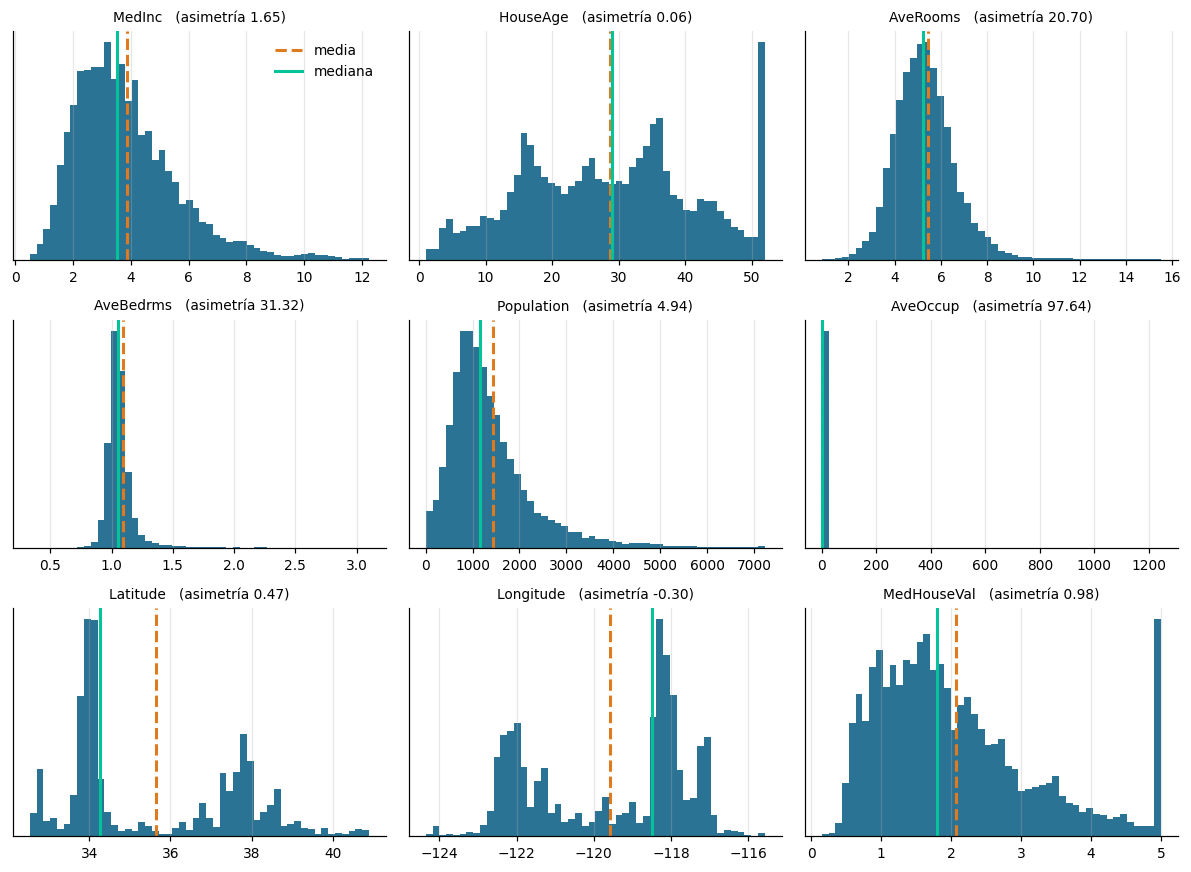

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, c in zip(axes.ravel(), df.columns):
    x = df[c]
    tope = 0
    if c == "AveOccup":
      tope = x.quantile(1.0)
    else:
      tope = x.quantile(0.995)                       # ✏️ prueba con 1.0 para AveOccup y compara
    ax.hist(x[x <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.axvline(x.mean(), color=NARANJA, lw=2, ls="--", label="media")
    ax.axvline(x.median(), color=VERDE, lw=2, label="mediana")
    ax.set_title(f"{c}   (asimetría {x.skew():.2f})", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.show()

✏️ **Pregunta 3.1.** Describe con una frase la forma de `MedInc`, `HouseAge`, `Population` y `MedHouseVal`.
¿Cuáles tienen una barra «de más» al extremo derecho? (La estudiaremos en la Parte 6.)

✏️ **Pregunta 3.2.** Cambia `tope = x.quantile(0.995)` por `x.quantile(1.0)` y mira `AveOccup`. ¿Qué pasa con el histograma y por qué?

**Respuesta:**

---
## Parte 4 — Identificar atípicos con boxplots y la regla del IQR

**Regla de Tukey.** Con $Q_1$, $Q_3$ y $\mathrm{IQR}=Q_3-Q_1$, un dato es atípico si cae fuera de

$$[\,Q_1-k\cdot\mathrm{IQR},\ \ Q_3+k\cdot\mathrm{IQR}\,],\qquad k=1.5\ (\text{atípico})\quad\text{o}\quad k=3\ (\text{atípico extremo}).$$

Primero comprobamos con datos simulados qué fracción marca la regla cuando **sí** conocemos la distribución.

In [ ]:
def cercas_iqr(s, k=1.5):
    '''Devuelve (cerca inferior, cerca superior) de la regla de Tukey.'''
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rng = np.random.default_rng(0)
for nombre, x in [("normal", rng.normal(size=100_000)), ("lognormal", rng.lognormal(size=100_000))]:
    lo, hi = cercas_iqr(pd.Series(x))
    print(f"{nombre:10s}: {100 * ((x < lo) | (x > hi)).mean():.2f} % de los datos fuera de las cercas")

✏️ **Pregunta 4.1.** En la normal, ¿qué porcentaje marca la regla? ¿Y en la lognormal (muy asimétrica)? ¿Qué te dice esto sobre interpretar
«porcentaje de atípicos» en variables con cola larga?

**Respuesta:**

In [ ]:
def tabla_atipicos(d, k=1.5):
    filas = []
    for c in d.columns:
        lo, hi = cercas_iqr(d[c], k)
        bajo, alto = int((d[c] < lo).sum()), int((d[c] > hi).sum())
        filas.append(dict(variable=c, cerca_inf=lo, cerca_sup=hi, n_bajo=bajo, n_alto=alto,
                          pct_atipicos=100 * (bajo + alto) / len(d), minimo=d[c].min(), maximo=d[c].max()))
    return pd.DataFrame(filas).set_index("variable")

K = 1.5                        # ✏️ cambia a 3.0 y vuelve a ejecutar esta celda y la siguiente
tabla = tabla_atipicos(df, K)
tabla.round(2)

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(11, 7))
for ax, c in zip(axes.ravel(), df.columns):
    ax.boxplot(df[c], vert=False, whis=K, patch_artist=True,
               boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
               flierprops=dict(marker="o", markersize=2, markerfacecolor="gray", markeredgecolor="none", alpha=0.4))
    ax.set_yticks([])
    ax.set_title(f"{c}: {tabla.loc[c, 'pct_atipicos']:.1f} % atípicos", fontsize=9)
plt.tight_layout()
plt.show()

✏️ **Pregunta 4.2.** Con $k=1.5$: ¿qué variable tiene el mayor *porcentaje* de atípicos? ¿Cuál tiene el valor más **lejano** (compara `maximo` con `cerca_sup`)?
¿Coinciden? ¿Por qué un porcentaje alto no implica necesariamente valores absurdos?

✏️ **Pregunta 4.3.** Repite con $k=3$. ¿Qué variables casi «se limpian» y cuáles conservan atípicos extremos? ¿Cuáles tienen **0 %** y por qué
(piensa en `Latitude`, `Longitude` y `HouseAge`)?

**Respuesta:**

---
## Parte 5 — Inspeccionar las filas extremas: ¿error, dato raro o tope?

La regla del IQR dice **qué es inusual**, no **qué es incorrecto**. Para decidir hay que mirar las filas y razonar con el contexto.
Una pista útil: el número de hogares de un distrito es aproximadamente `Population / AveOccup`.

In [ ]:
ext = df.nlargest(5, "AveOccup").copy()
ext["hogares (aprox.)"] = ext["Population"] / ext["AveOccup"]
print("Las 5 filas con más ocupantes por hogar:")
ext[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "MedHouseVal"]].round(1)

In [ ]:
ext2 = df.nlargest(5, "AveRooms").copy()
ext2["hogares (aprox.)"] = ext2["Population"] / ext2["AveOccup"]
print("Las 5 filas con más habitaciones por hogar:")
ext2[["Population", "AveOccup", "hogares (aprox.)", "AveRooms", "AveBedrms", "MedHouseVal"]].round(1)

✏️ **Pregunta 5.1.** Para cada uno de estos casos, clasifícalo y justifica: **(a)** error de captura / imposible, **(b)** dato real pero raro,
**(c)** tope o censura. Fíjate en los hogares aproximados: un distrito con 7 460 personas y ≈6 hogares, ¿qué tipo de lugar podría ser?
(pista: residencias universitarias, cárceles, cuarteles…) ¿Qué distritos con muchas habitaciones por hogar y muy poca población podrían ser?

✏️ **Pregunta 5.2.** ¿Tienen sentido estos distritos para un modelo que predice el **valor de la vivienda** en zonas residenciales normales?
Propón una regla (por ejemplo, un mínimo de hogares) para marcarlos o excluirlos, **y anota cuántas filas afectaría**.

**Respuesta:**

In [ ]:
# ✏️ Pregunta 5.2: prueba tu regla aquí (ejemplo: marcar distritos con menos de 10 hogares)
hogares = df["Population"] / df["AveOccup"]
marca = hogares < 10
print(f"Filas marcadas: {marca.sum()} de {len(df)}  ({100 * marca.mean():.2f} %)")
df.loc[marca, ["Population", "AveOccup", "AveRooms", "MedHouseVal"]].describe().round(1)

---
## Parte 6 — Topes (censura): los picos en 5.0 y 52

En los histogramas había una barra extra al final de `MedHouseVal` y de `HouseAge`: valores **truncados** por la forma en que se publicó
el censo (valores mayores se registran como el tope). No son «atípicos»: son datos **censurados**.

In [ ]:
topes = {"MedHouseVal": 5.0, "HouseAge": 52, "MedInc": 15.0}
for c, tope in topes.items():
    n = int((df[c] >= tope).sum())
    print(f"{c:12s}: {n:5d} filas ≥ {tope}  ({100 * n / len(df):.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, c in zip(axes, ["MedHouseVal", "HouseAge"]):
    ax.hist(df[c], bins=60, color=AZUL, alpha=0.9)
    ax.axvline(topes[c], color=ROJO, ls="--", lw=1.5)
    ax.set_title(f"{c}: pico en el tope {topes[c]}")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
# ¿Cómo cambia una correlación si «quitamos» las filas con tope?
sin_tope = df[df["MedHouseVal"] < 5.0]
print("r(MedInc, MedHouseVal) con topes :", round(df["MedInc"].corr(df["MedHouseVal"]), 3))
print("r(MedInc, MedHouseVal) sin topes :", round(sin_tope["MedInc"].corr(sin_tope["MedHouseVal"]), 3))
print("Filas que se perderían:", len(df) - len(sin_tope))

✏️ **Pregunta 6.1.** ¿Por qué no es lo mismo un tope que un atípico? ¿Cuántos distritos tienen `MedHouseVal` en el tope? ¿Y `HouseAge`?

✏️ **Pregunta 6.2.** La correlación baja al quitar los topes. ¿Significa que «con topes» está mal? Pista: los distritos más caros e ingresos más altos son
justo los que fueron truncados. ¿Qué **sesgo** introduce *borrar* esas filas? Propón una alternativa (por ejemplo, agregar un indicador `es_tope`
o reportar el desempeño del modelo también en la zona no truncada).

**Respuesta:**

---
## Parte 7 — Transformar o recortar: ¿qué cambia?

Tres tratamientos habituales para colas largas:

| Tratamiento | Qué hace | Cuándo es razonable |
|---|---|---|
| **Winsorizar** (`clip`) | trunca en las cercas del IQR | los extremos son raros/dudosos pero no queremos perder filas |
| **Logaritmo** | comprime la cola derecha | variable positiva con cola larga y efectos multiplicativos |
| **Nada** | deja el dato igual | el valor extremo es real y relevante |

In [ ]:
def logaritmo(s):
    # conteos (pueden valer 0): log(1 + x); promedios estrictamente positivos: log(x)
    return np.log1p(s) if s.name == "Population" else np.log(s)

def efecto(c, k=3.0):
    x = df[c]
    lo, hi = cercas_iqr(x, k)
    variantes = {
        "original": x,
        f"clip (k={k})": x.clip(lo, hi),
        "log": logaritmo(x),
    }
    filas = []
    for nombre, v in variantes.items():
        filas.append(dict(version=nombre, asimetria=v.skew(), curtosis_exc=v.kurt(), r_con_objetivo=v.corr(df["MedHouseVal"]),
                          spearman=v.corr(df["MedHouseVal"], method="spearman")))
    return pd.DataFrame(filas).set_index("version"), variantes

for c in ["AveOccup", "AveRooms", "Population"]:
    t, _ = efecto(c)
    print(f"── {c}")
    print(t.round(3).to_string(), "\n")

In [ ]:
t, var = efecto("AveOccup")
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, v) in zip(axes, var.items()):
    tope = v.quantile(0.995) if nombre == "original" else v.max()
    ax.hist(v[v <= tope], bins=50, color=AZUL, alpha=0.85)
    ax.set_title(f"AveOccup — {nombre}\nasimetría = {v.skew():.2f}", fontsize=9)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

✏️ **Pregunta 7.1.** Mira `AveOccup`: ¿qué le pasa a la correlación de Pearson con `MedHouseVal` al recortar? ¿Y a la de Spearman?
¿Qué te dice eso sobre lo que hacían los valores extremos con $r$? (Pista: el logaritmo y el recorte casi no cambian el *orden* de los datos; ¿por qué Spearman casi no se mueve?)

✏️ **Pregunta 7.2.** Para `Population` el logaritmo deja la asimetría **negativa**. ¿Qué significa que se haya «pasado»? ¿Es un problema?

✏️ **Pregunta 7.3.** Cambia `k` en `efecto(c, k=3.0)` por `1.5` y compara. ¿Cuánta información pierdes al recortar con un $k$ más agresivo?

**Respuesta:**

### Aplicar sus decisiones

Completa el diccionario con la acción que elijas para cada variable: `"ninguno"`, `"clip"` o `"log"`.
La función `aplicar` crea una copia transformada; luego comparamos la asimetría antes y después.

> ⚠️ **Fugas.** Aquí calculamos las cercas con *todos* los datos para simplificar. En un proyecto real, las cercas (y medias, etc.) se
> calculan **solo con el conjunto de entrenamiento** y se reutilizan en validación y prueba (como vimos en la sesión 1).

In [ ]:
decisiones = {        # ✏️ cambia las decisiones y vuelve a ejecutar esta celda y las siguientes
    "MedInc": "ninguno",
    "HouseAge": "ninguno",
    "AveRooms": "clip",
    "AveBedrms": "clip",
    "Population": "log",
    "AveOccup": "clip",
    "Latitude": "ninguno",
    "Longitude": "ninguno",
}

def aplicar(d, decisiones, k=3.0):
    out = d.copy()
    for c, accion in decisiones.items():
        if accion == "clip":
            out[c] = out[c].clip(*cercas_iqr(out[c], k))
        elif accion == "log":
            out[c] = logaritmo(out[c])
        elif accion != "ninguno":
            raise ValueError(f"acción desconocida para {c}: {accion!r}")
    return out

df_t = aplicar(df, decisiones)
comp = pd.DataFrame({"asimetria_antes": df.skew(), "asimetria_despues": df_t.skew(),
                     "curtosis_antes": df.kurt(), "curtosis_despues": df_t.kurt()})
comp.round(2)

---
## Parte 8 — Análisis bivariado

Con $n=20\,640$ puntos, una dispersión simple se **satura** (puntos encimados). Comparamos con un *hexbin*, que cuenta puntos por celda,
y miramos `MedHouseVal` por grupos de ingreso.

In [ ]:
X_NOMBRE = "MedInc"        # ✏️ cambia la variable y vuelve a ejecutar (prueba AveOccup, HouseAge, Latitude…)
Y_NOMBRE = "MedHouseVal"

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(df[X_NOMBRE], df[Y_NOMBRE], s=2, color=AZUL, alpha=0.4, lw=0)
axes[0].set_title("dispersión: puntos encimados")
hb = axes[1].hexbin(df[X_NOMBRE], df[Y_NOMBRE], gridsize=40, cmap="YlGnBu", mincnt=1, bins="log")
axes[1].set_title("hexbin: densidad (escala log)")
grupos = pd.qcut(df[X_NOMBRE], 4, labels=["Q1", "Q2", "Q3", "Q4"])
axes[2].boxplot([df.loc[grupos == g, Y_NOMBRE] for g in grupos.cat.categories], patch_artist=True,
                boxprops=dict(facecolor="#9FD0E0", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
                flierprops=dict(markersize=1.5, alpha=0.3))
axes[2].set_xticklabels(grupos.cat.categories)
axes[2].set_title(f"{Y_NOMBRE} por cuartil de {X_NOMBRE}")
for ax in axes[:2]:
    ax.set_xlabel(X_NOMBRE); ax.set_ylabel(Y_NOMBRE)
plt.tight_layout()
plt.show()
print(f"r de Pearson = {df[X_NOMBRE].corr(df[Y_NOMBRE]):.3f}    rho de Spearman = {df[X_NOMBRE].corr(df[Y_NOMBRE], method='spearman'):.3f}")

In [ ]:
# Mapa: la ubicación también cuenta
plt.figure(figsize=(5, 5))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["MedHouseVal"], s=2, cmap="YlGnBu")
plt.colorbar(sc, label="MedHouseVal")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.gca().set_aspect(1.2)
plt.grid(False)
plt.show()

✏️ **Pregunta 8.1.** En la primera gráfica (`MedInc` vs `MedHouseVal`), ¿qué es la línea horizontal de puntos arriba? ¿Cómo la relacionas con la Parte 6?
¿Qué ventaja da el hexbin sobre la dispersión?

✏️ **Pregunta 8.2.** ¿Cómo cambia la mediana de `MedHouseVal` al pasar de Q1 a Q4 de ingreso? ¿Es monótona?

✏️ **Pregunta 8.3.** En el mapa, ¿dónde están los distritos más caros? ¿Qué otro factor (distinto de `MedInc`)
podría estar influyendo tanto en el ingreso como en el precio? (recuerda *correlación ≠ causalidad*)

**Respuesta:**

---
## Parte 9 — Matriz de correlación, heatmap y multicolinealidad

Con 9 variables hay $\binom92=36$ pares. La matriz $R=\frac1{n-1}Z^\top Z$ (con $Z$ las columnas estandarizadas) los resume.
Seguimos las buenas prácticas de la presentación: escala **divergente centrada en 0**, solo el **triángulo inferior** y **valores anotados**.

In [ ]:
def heatmap(Cm, ax, titulo):
    mask = np.triu(np.ones(Cm.shape, dtype=bool), k=1)           # oculta el triángulo superior (es repetido)
    im = ax.imshow(np.ma.array(Cm.values, mask=mask), cmap="RdBu", vmin=-1, vmax=1)
    n = len(Cm)
    ax.set_xticks(range(n)); ax.set_xticklabels(Cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(Cm.index)
    ax.grid(False)
    for i in range(n):
        for j in range(i + 1):
            v = Cm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    return im

Cp = df.corr()                         # Pearson
Cs = df.corr(method="spearman")        # Spearman = Pearson de los rangos
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
heatmap(Cp, axes[0], "Pearson")
im = heatmap(Cs, axes[1], "Spearman")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlación")
plt.show()

In [ ]:
# Los pares más fuertes (sin repetir y sin la diagonal)
tri = np.tril(np.ones(Cp.shape, dtype=bool), k=-1)
pares = Cp.where(tri).stack().rename("pearson").to_frame()
pares["spearman"] = Cs.where(tri).stack()
pares["|pearson|"] = pares["pearson"].abs()
pares.sort_values("|pearson|", ascending=False).head(6).round(2)

In [ ]:
# Pearson vs Spearman con el objetivo: ¿en qué variables difieren más?
vs = pd.DataFrame({"pearson": Cp["MedHouseVal"], "spearman": Cs["MedHouseVal"]}).drop("MedHouseVal")
vs["diferencia"] = (vs["spearman"] - vs["pearson"]).abs()
vs.sort_values("diferencia", ascending=False).round(2)

✏️ **Pregunta 9.1.** ¿Qué variable se correlaciona más con el objetivo? ¿Cuál es el par de variables **predictoras** más correlacionado (Pearson)? ¿Y el segundo?
¿Tienen sentido en el contexto (geografía, tamaño de las viviendas)?

✏️ **Pregunta 9.2.** ¿En qué variable difieren más Pearson y Spearman con el objetivo? Mira también el par `AveBedrms`–`AveRooms`: ¿qué le pasa a su correlación al pasar de Pearson a Spearman?
Conecta con lo que viste en las Partes 4, 5 y 7: ¿qué estaban haciendo los atípicos con $r$? ¿Qué implica para decir que dos variables son «redundantes»?

**Respuesta:**

### Multicolinealidad

Con predictores muy correlacionados, los coeficientes de una regresión lineal se vuelven inestables. El **factor de inflación de la varianza**
mide qué tan bien se explica cada predictor con los demás:

$$\mathrm{VIF}_j=\frac{1}{1-R_j^2}\;=\;\big[R^{-1}\big]_{jj}\quad(\text{el }j\text{-ésimo elemento de la diagonal de la inversa de la matriz de correlación}).$$

Regla práctica: $\mathrm{VIF}>5$–$10$ es una alerta.

In [ ]:
def vif(X):
    R = X.corr().values
    return pd.Series(np.diag(np.linalg.inv(R)), index=X.columns, name="VIF")

X = df.drop(columns="MedHouseVal")
vif(X).round(1)

✏️ **Pregunta 9.3.** ¿Qué variables tienen VIF alto? ¿Las habías anticipado con el heatmap? ¿Esa colinealidad es «real» para todo el conjunto o la crean unos pocos distritos extremos? (revisa los Spearman de la Parte 9)

✏️ **Pregunta 9.4.** Quita **una** de las variables con VIF alto (la que consideres más redundante, p. ej. `AveBedrms`) en la celda de abajo y vuelve a calcular.
¿Cuánto baja el VIF de su «pareja»? ¿Qué variable elegirías conservar y por qué?

**Respuesta:**

In [ ]:
# ✏️ Pregunta 9.4: elige qué variable quitar y compara
a_quitar = ["AveBedrms"]
vif(X.drop(columns=a_quitar)).round(1)

---
## Parte 10 — Resumen y entregable

Rellena la tabla con **una fila por variable predictora**. La columna `pct_atipicos` ya está calculada con la regla del IQR ($k=1.5$);
las columnas `decision` y `justificacion` las completas tú.

| variable | % atípicos | decisión | justificación |
|---|---|---|---|
| *(ejemplo)* `AveOccup` | 3.4 | `clip` en $3\cdot$IQR | casi todos los distritos tienen ≈3 ocupantes; los valores > 50 corresponden a distritos con muy pocos hogares (residencias colectivas) y arrastran la media y a $r$ |

Una buena justificación responde: **¿por qué es (o no) un error?**, **¿qué pasaría con el análisis si lo dejamos?** y **¿cómo documento la decisión?**

In [ ]:
entrega = tabla_atipicos(df.drop(columns="MedHouseVal"), 1.5)[["pct_atipicos"]].round(1).copy()
entrega["decision"] = "(completa: ninguno / clip / log / excluir / indicador)"
entrega["justificacion"] = "(completa)"
pd.set_option("display.max_colwidth", 80)
entrega

In [ ]:
# Cuando termines, guarda la tabla y súbela junto con este notebook
# (edita primero las columnas «decision» y «justificacion» en la celda anterior, p. ej. con entrega.loc["AveOccup", "decision"] = "clip")
entrega.to_csv("entregable_unidad1.csv", encoding="utf-8")
print("Guardado: entregable_unidad1.csv")

### Reflexión final (3–5 líneas)

1. ¿Qué hallazgo del EDA **cambiaría** la forma en que entrenarías un modelo para predecir `MedHouseVal`?
2. ¿Qué decisión de la tabla es la más **discutible** y qué evidencia adicional pedirías?
3. Dos *trampas* de la presentación que aparecieron en este conjunto de datos (por ejemplo: topes, correlaciones aplastadas por atípicos, multicolinealidad…).

**Respuesta:**

---
### Reto opcional

Compara la regla del IQR con la regla del puntaje $z$ ($|z|>3$) en `AveOccup` y en `MedInc`: ¿cuántos puntos marca cada una?
¿Cuál es más sensible a los propios atípicos, y por qué? (Pista: el $z$ usa $\bar x$ y $s$, que los atípicos *contaminan*; el IQR usa cuartiles.)

In [ ]:
# Reto opcional: IQR vs |z| > 3
for c in ["AveOccup", "MedInc"]:
    x = df[c]
    lo, hi = cercas_iqr(x, 1.5)
    n_iqr = int(((x < lo) | (x > hi)).sum())
    n_z = int((((x - x.mean()) / x.std()).abs() > 3).sum())
    print(f"{c:9s}: IQR(1.5) marca {n_iqr:5d}   |z|>3 marca {n_z:5d}")